In [21]:
# Data manipulation
import os
os.environ["OMP_NUM_THREADS"] = "1"
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("All libraries imported successfully!")

All libraries imported successfully!


In [22]:
df = pd.read_csv("Mall_Customers.csv")
# Display the first 5 rows
print(df.head())

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check column names and data types
print(df.info())



   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
Dataset shape: (200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None


In [23]:
# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Statistical summary
print(df.describe())


Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate rows: 0
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.500000   36.000000           61.500000               50.000000
75%    150.250000   49.000000           78.000000               73.000000
max    200.000000   70.000000          137.000000               99.000000


In [24]:
print("Minimum values:")
print(df[["Age", "Annual Income (k$)",
          "Spending Score (1-100)"]].min())

print("\nMaximum values:")
print(df[["Age", "Annual Income (k$)",
          "Spending Score (1-100)"]].max())

print("\nData types:")
print(df.dtypes)

Minimum values:
Age                       18
Annual Income (k$)        15
Spending Score (1-100)     1
dtype: int64

Maximum values:
Age                        70
Annual Income (k$)        137
Spending Score (1-100)     99
dtype: int64

Data types:
CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object


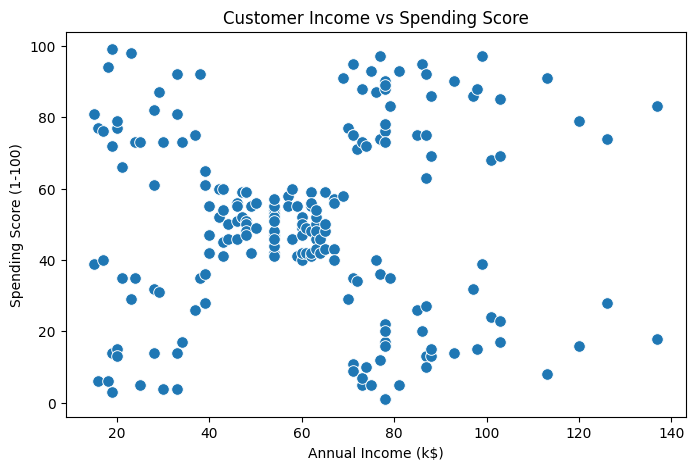

In [25]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    s=70
)

plt.title("Customer Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()

In [26]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]

X = df[features]

print("Selected features:")
print(X.head())

print("\nMissing values:")
print(X.isnull().sum())

print("\nData shape:", X.shape)

Selected features:
   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40

Missing values:
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Data shape: (200, 2)


In [27]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled data:")
print(X_scaled[:5])

Scaled data:
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


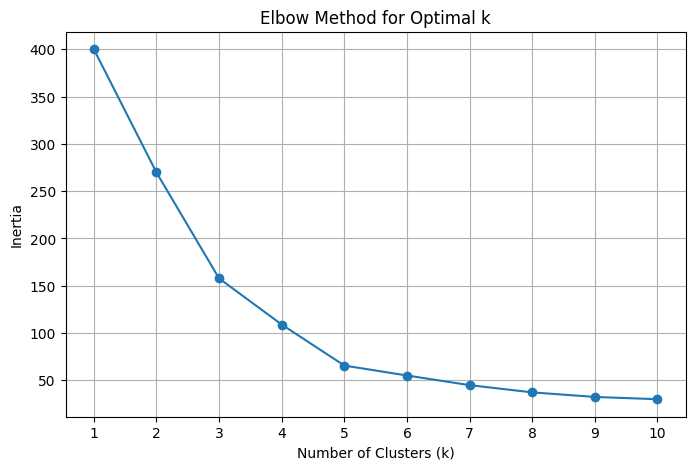

In [28]:
inertia = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia, marker="o")

plt.title("Elbow Method for Optimal k")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(k_values)
plt.grid(True)
plt.show()

In [29]:
for k, value in zip(k_values, inertia):
    print(f"k = {k}: Inertia = {value:.2f}")

k = 1: Inertia = 400.00
k = 2: Inertia = 269.69
k = 3: Inertia = 157.70
k = 4: Inertia = 108.92
k = 5: Inertia = 65.57
k = 6: Inertia = 55.06
k = 7: Inertia = 44.86
k = 8: Inertia = 37.23
k = 9: Inertia = 32.39
k = 10: Inertia = 29.98


In [30]:
for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)

    print(f"k = {k}: Silhouette Score = {score:.3f}")

k = 2: Silhouette Score = 0.321
k = 3: Silhouette Score = 0.467
k = 4: Silhouette Score = 0.494
k = 5: Silhouette Score = 0.555
k = 6: Silhouette Score = 0.540
k = 7: Silhouette Score = 0.528
k = 8: Silhouette Score = 0.455
k = 9: Silhouette Score = 0.457
k = 10: Silhouette Score = 0.443


In [31]:
# Create the final K-Means model
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)


df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Customers in each cluster:")
print(df["Cluster"].value_counts().sort_index())

Customers in each cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


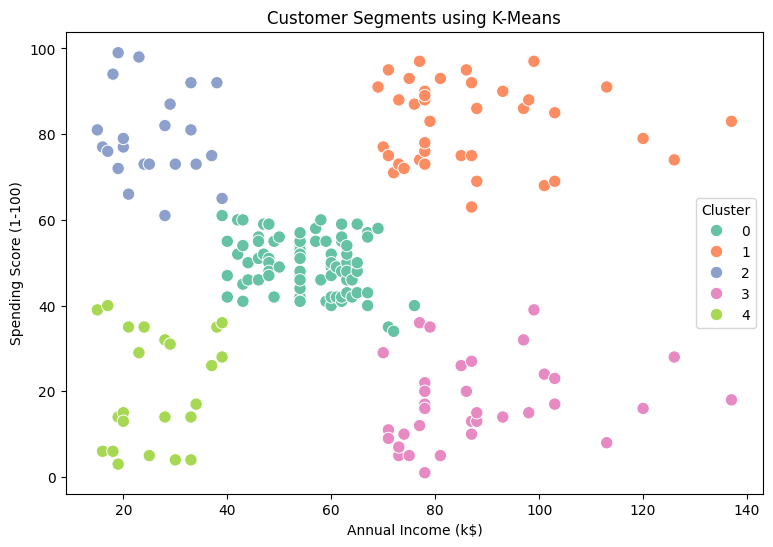

In [32]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="Set2",
    s=80
)

plt.title("Customer Segments using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.show()

In [33]:
cluster_summary = df.groupby("Cluster")[
    [
        "Age",
        "Annual Income (k$)",
        "Spending Score (1-100)"
    ]
].mean().round(2)

print(cluster_summary)

           Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                   
0        42.72               55.30                   49.52
1        32.69               86.54                   82.13
2        25.27               25.73                   79.36
3        41.11               88.20                   17.11
4        45.22               26.30                   20.91


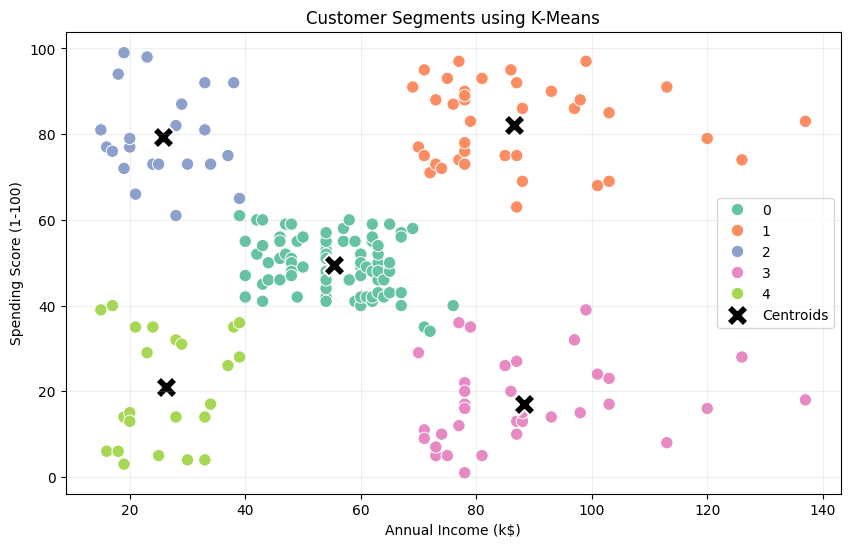

In [34]:
# Get cluster centers and convert them to original scale
centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="Set2",
    s=80
)

# Plot cluster centers
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=250,
    color="black",
    edgecolor="white",
    linewidth=1.5,
    label="Centroids"
)

plt.title("Customer Segments using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

# Bounus Task (DBSCAN Clustering)

DBSCAN (Density-Based Spatial Clustering of Applications with Noise) is a density-based clustering algorithm.

Unlike K-Means, DBSCAN does not require the number of clusters to be specified in advance. Instead, it identifies clusters based on the density of nearby data points.

### Main Parameters

- **eps:** The maximum distance between two points for them to be considered neighbors.
- **min_samples:** The minimum number of nearby samples required to form a dense region.

DBSCAN can also identify points that do not belong to any cluster. These points are labeled `-1` and are treated as noise by the algorithm.

The results depend on the selected parameters, so different values may need to be tested.

### Why Use DBSCAN?

DBSCAN provides an alternative to K-Means and can help identify dense customer groups and potential outliers. The results of both algorithms can be compared to better understand the structure of the dataset.


DBSCAN Cluster Counts:
DBSCAN_Cluster
-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, dtype: int64


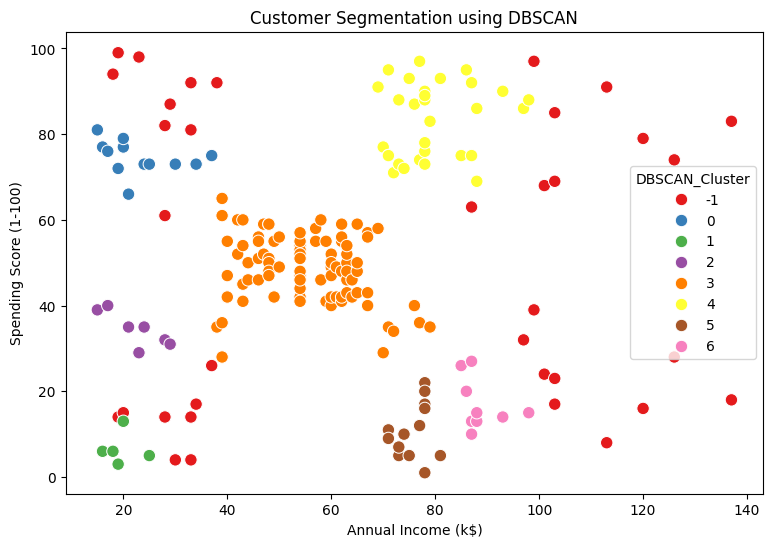

In [35]:
# Apply DBSCAN
dbscan = DBSCAN(
    eps=0.3,
    min_samples=5
)

df["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

# Count customers in each cluster
print("DBSCAN Cluster Counts:")
print(df["DBSCAN_Cluster"].value_counts().sort_index())

# Visualize DBSCAN clusters
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="DBSCAN_Cluster",
    palette="Set1",
    s=80
)

plt.title("Customer Segmentation using DBSCAN")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()

## Comparing K-Means and DBSCAN

K-Means and DBSCAN use different approaches to identify customer groups.

| Aspect | K-Means | DBSCAN |
|---|---|---|
| Clustering approach | Centroid-based | Density-based |
| Number of clusters | Specified in advance | Determined from data density |
| Noise detection | Not a built-in feature | Supported |
| Main parameters | Number of clusters | `eps` and `min_samples` |

The clustering plots and evaluation metrics are examined to understand the strengths and limitations of each algorithm.

Silhouette Score can be used as one evaluation measure when the resulting labels contain at least two valid clusters. However, the scores should be interpreted carefully, especially when DBSCAN labels some points as noise.


In [36]:
labels = df["DBSCAN_Cluster"]
n_clusters = len(set(labels) - {-1})

if n_clusters >= 2:
    mask = labels != -1

    if len(set(labels[mask])) >= 2:
        score = silhouette_score(
            X_scaled[mask],
            labels[mask]
        )
        print("DBSCAN Silhouette Score:", round(score, 3))
    else:
        print("Not enough clusters for evaluation.")
else:
    print("DBSCAN did not find enough clusters.")

DBSCAN Silhouette Score: 0.524


## Conclusion

This project applies unsupervised machine learning techniques to segment mall customers using annual income and spending score.

K-Means is used to create customer groups with a predefined number of clusters, while DBSCAN is explored as a density-based alternative that can identify noise points.

The clustering visualizations and evaluation metrics help assess the resulting groups and understand customer behavior patterns.

From a business perspective, the identified segments may support targeted marketing campaigns, customer loyalty programs, and promotional strategies.

The project also includes a Streamlit application that allows users to enter customer information and obtain a K-Means cluster prediction.

Overall, this project demonstrates how clustering techniques can be used to explore customer data and support data-driven marketing decisions.


In [16]:
import joblib

joblib.dump(kmeans, "kmeans_model.pkl")
joblib.dump(scaler, "scaler.pkl")

print("Model and scaler saved successfully!")

Model and scaler saved successfully!


In [37]:
import joblib
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=0.3,
    min_samples=5
)

dbscan.fit(X_scaled)

joblib.dump(dbscan, "dbscan_model.pkl")

['dbscan_model.pkl']